# 09 — Distribuições Conjuntas

Nos notebooks 07 e 08, cada variável aleatória vivia sozinha. Mas um dataset de ML tem **várias colunas ao mesmo tempo**, e o que interessa é justamente **como elas se relacionam**: o modelo aprende o alvo a partir dos atributos porque eles **variam juntos**.

Este notebook é a versão probabilística do notebook 04 (relações entre variáveis). Vamos:
- Montar a **distribuição conjunta** de duas variáveis e extrair dela as **marginais** e as **condicionais**
- Calcular a **esperança condicional**, a ideia por trás de toda regressão
- Ver a **covariância** de variáveis aleatórias e a variância de uma soma
- Descobrir que **correlação zero não significa independência**
- Conhecer a **normal multivariada** e a **matriz de covariância**
- Encontrar as **direções principais** dos dados (uma prévia do PCA) e a **distância de Mahalanobis**

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA   # só para conferir as direções principais no fim do notebook

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

gorjetas = sns.load_dataset("tips")
pinguins = sns.load_dataset("penguins").dropna()

## 🎓 Conceito: distribuição conjunta, marginal e condicional

Para duas variáveis discretas $X$ e $Y$:
- A **distribuição conjunta** dá a probabilidade de cada **par** de valores: $P(X = x, Y = y)$. É uma tabela de contingência dividida pelo total: a soma de **todas** as células é 1.
- A **distribuição marginal** de $X$ ignora $Y$: soma cada linha da tabela, $P(X = x) = \sum_y P(X = x, Y = y)$. O nome vem de que esses totais ficam nas **margens** da tabela.
- A **distribuição condicional** de $Y$ dado $X = x$ é a linha de $x$ dividida pelo seu total: $P(Y = y \mid X = x) = P(X = x, Y = y) / P(X = x)$. É a probabilidade condicional do notebook 06, para todos os valores de uma vez.

Vamos usar o tamanho da mesa ($X$, agrupando mesas de 4 ou mais pessoas) e a refeição ($Y$).

In [2]:
# np.minimum(x, 4) troca todo valor acima de 4 por 4; depois viram texto para rotular "4+".
tamanho = np.minimum(gorjetas["size"], 4).astype(str).str.replace("4", "4+")
conjunta = pd.crosstab(tamanho, gorjetas["time"], normalize="all")   # normalize="all": divide pelo total geral
conjunta.index.name = "pessoas"

print("Distribuição conjunta P(X, Y):")
print(conjunta, f"\nSoma de todas as células: {conjunta.values.sum():.4f}\n")

marginal_x = conjunta.sum(axis=1)   # soma das linhas → P(X)
marginal_y = conjunta.sum(axis=0)   # soma das colunas → P(Y)
print("Marginal de X (pessoas):", marginal_x.round(4).to_dict())   # .to_dict() mostra como dicionário
print("Marginal de Y (refeição):", marginal_y.round(4).to_dict(), "\n")

# Condicional P(Y | X): cada linha dividida pelo seu total. .div(..., axis=0) divide linha a linha.
condicional = conjunta.div(marginal_x, axis=0)
print("Condicional P(refeição | pessoas):")
print(condicional)

Distribuição conjunta P(X, Y):
time      Lunch  Dinner
pessoas                
1        0.0082  0.0082
2        0.2131  0.4262
3        0.0205  0.1352
4+       0.0369  0.1516 
Soma de todas as células: 1.0000

Marginal de X (pessoas): {'1': 0.0164, '2': 0.6393, '3': 0.1557, '4+': 0.1885}
Marginal de Y (refeição): {'Lunch': 0.2787, 'Dinner': 0.7213} 

Condicional P(refeição | pessoas):
time      Lunch  Dinner
pessoas                
1        0.5000  0.5000
2        0.3333  0.6667
3        0.1316  0.8684
4+       0.1957  0.8043


**Conclusão:** a tabela conjunta soma **1** e cada célula é a chance de uma combinação: por exemplo, **42,6%** das mesas são de 2 pessoas no jantar. As marginais são os totais: **63,9%** das mesas têm 2 pessoas, e **72,1%** são de jantar.

As condicionais mostram que a refeição depende do tamanho da mesa: entre as mesas de **2 pessoas**, um terço (**33,3%**) é de almoço; entre as de **3 pessoas**, só **13,2%**. Mesas maiores aparecem mais no jantar. (A linha de 1 pessoa, com 50% / 50%, se apoia em apenas **4 mesas**: a fração 0,0164 da marginal.)

## 🎓 Conceito: esperança condicional

A **esperança condicional** $E[Y \mid X = x]$ é o valor esperado de $Y$ **entre os casos em que $X = x$**. Calculando-a para cada $x$, obtemos uma **função** de $x$: a média de $Y$ "em cada fatia" de $X$.

Esse é o conceito central da regressão: quando o ML-01 prevê o valor de uma casa a partir dos atributos, o que o modelo tenta aprender é exatamente $E[\text{valor} \mid \text{atributos}]$. (E, como vimos no notebook 02, a média é a melhor previsão quando o erro é medido pelo quadrado.)

      count    mean
size               
1         4  1.4375
2       156  2.5823
3        38  3.3932
4        37  4.1354
5         5  4.0280
6         4  5.2250


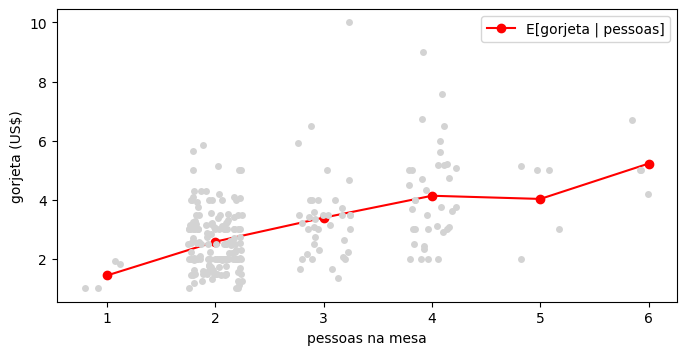

Média ponderada das condicionais: 2.9983   média geral: 2.9983


In [3]:
# E[gorjeta | tamanho da mesa]: a média da gorjeta em cada grupo.
esperanca_cond = gorjetas.groupby("size")["tip"].agg(["count", "mean"])
print(esperanca_cond)

fig, ax = plt.subplots(figsize=(8, 3.8))
# stripplot espalha um pouco os pontos na horizontal (jitter) para não ficarem empilhados.
sns.stripplot(data=gorjetas, x="size", y="tip", color="lightgray", jitter=0.25, ax=ax)
ax.plot(range(len(esperanca_cond)), esperanca_cond["mean"], "ro-", label="E[gorjeta | pessoas]")
ax.set_xlabel("pessoas na mesa")
ax.set_ylabel("gorjeta (US$)")
ax.legend()
plt.show()

# A lei da esperança total: a média das médias condicionais, ponderada pelo tamanho de cada grupo, é a média geral.
media_ponderada = np.sum(esperanca_cond["mean"] * esperanca_cond["count"]) / esperanca_cond["count"].sum()
print(f"Média ponderada das condicionais: {media_ponderada:.4f}   média geral: {gorjetas['tip'].mean():.4f}")

**Conclusão:** a gorjeta média cresce com o tamanho da mesa: **US\$ 1,44** para 1 pessoa, **2,58** para 2, **3,39** para 3 e **4,14** para 4. A pequena queda de 4 para 5 pessoas (4,03) se apoia em só 5 mesas e provavelmente é ruído; com 6 pessoas, a média volta a subir (5,23, com 4 mesas). Em volta de cada ponto vermelho há bastante dispersão: $E[Y \mid X]$ é a melhor previsão **média**, mas cada mesa individual varia muito.

A **lei da esperança total** confere: a média das médias condicionais, ponderada pelo número de mesas, é **2,9983**, exatamente a média geral. É a lei da probabilidade total do notebook 06, aplicada a médias.

## 🎓 Conceito: covariância e a variância de uma soma

A covariância do notebook 04 também existe para variáveis aleatórias: $\text{Cov}(X, Y) = E[(X - E[X])(Y - E[Y])]$. Com ela, completamos a regra da variância de uma soma do notebook 07, agora **sem** exigir independência:

$$\text{Var}(X + Y) = \text{Var}(X) + \text{Var}(Y) + 2\,\text{Cov}(X, Y)$$

Se $X$ e $Y$ variam juntas (covariância positiva), a soma varia **mais** que a soma das variâncias; se uma compensa a outra (covariância negativa), varia **menos**. É o princípio da **diversificação** de investimentos: misturar ativos que não sobem e descem juntos reduz o risco.

In [4]:
conta = gorjetas["total_bill"]
gorjeta = gorjetas["tip"]
total_pago = conta + gorjeta

print(f"Var(conta) + Var(gorjeta)                  = {conta.var() + gorjeta.var():.3f}")
print(f"Var(conta) + Var(gorjeta) + 2·Cov          = {conta.var() + gorjeta.var() + 2 * conta.cov(gorjeta):.3f}")
print(f"Var(conta + gorjeta), calculada diretamente = {total_pago.var():.3f}")

Var(conta) + Var(gorjeta)                  = 81.167
Var(conta) + Var(gorjeta) + 2·Cov          = 97.814
Var(conta + gorjeta), calculada diretamente = 97.814


**Conclusão:** somar só as variâncias dá **81,17**, mas a variância do total pago é **97,81**. A diferença é o termo $2\,\text{Cov}$: como a conta e a gorjeta crescem juntas (covariância positiva, 8,32 no notebook 04), o total varia **mais** do que se elas fossem independentes. Com o termo de covariância, a fórmula bate exatamente com o cálculo direto.

## 🎓 Conceito: correlação zero não é independência

Se $X$ e $Y$ são independentes, a covariância (e a correlação) é zero. Mas o contrário **não vale**: a covariância só mede relações **lineares**. Vimos isso na parábola do notebook 04. Agora, um caso extremo: $Y = X^2$. $Y$ é **completamente determinada** por $X$, e mesmo assim a correlação é zero.

In [5]:
x = rng.normal(size=100_000)
y = x ** 2
print(f"Correlação entre X e X²: {np.corrcoef(x, y)[0, 1]:.4f}")   # corrcoef: matriz de correlação do numpy

# Mas a distribuição de Y muda completamente conforme X: compare Y quando |X| < 0,5 e quando |X| > 2.
print(f"E[Y | |X| < 0,5] = {y[np.abs(x) < 0.5].mean():.3f}")
print(f"E[Y | |X| > 2]   = {y[np.abs(x) > 2].mean():.3f}")

Correlação entre X e X²: -0.0011
E[Y | |X| < 0,5] = 0.080
E[Y | |X| > 2]   = 5.783


**Conclusão:** a correlação entre $X$ e $X^2$ é praticamente zero (**−0,001**), mas as duas variáveis são **totalmente dependentes**: quando $|X| < 0{,}5$, $Y$ vale em média **0,08**; quando $|X| > 2$, vale em média **5,78**. A correlação não vê nada porque a relação tem forma de "U": do lado negativo de $X$, $Y$ desce; do positivo, sobe; e as duas tendências se cancelam.

Regra: **independência ⇒ correlação zero**, mas **correlação zero ⇏ independência**. Para detectar relações não lineares, existem medidas como a **informação mútua**, que veremos no notebook 15.

## 🎓 Conceito: normal multivariada e matriz de covariância

A **normal multivariada** é a generalização da normal para várias variáveis ao mesmo tempo. Para duas variáveis, ela é uma "montanha" em forma de sino, e seus parâmetros são:
- o **vetor de médias** $\boldsymbol{\mu} = (\mu_X, \mu_Y)$, o centro da montanha;
- a **matriz de covariância** $\Sigma$, que diz a forma e a inclinação da montanha:
$$\Sigma = \begin{pmatrix} \text{Var}(X) & \text{Cov}(X, Y) \\ \text{Cov}(X, Y) & \text{Var}(Y) \end{pmatrix}$$

Vista de cima, cada "curva de nível" da montanha é uma **elipse**. Com covariância zero, a elipse fica alinhada com os eixos; com covariância positiva, inclina para cima; com negativa, para baixo.

Duas propriedades muito úteis:
- As **marginais** são normais.
- As **condicionais** também são normais, e a média de $Y$ dado $X = x$ é uma **reta** em $x$: $E[Y \mid X = x] = \mu_Y + \rho\,\frac{\sigma_Y}{\sigma_X}(x - \mu_X)$. É exatamente a **regressão linear**!

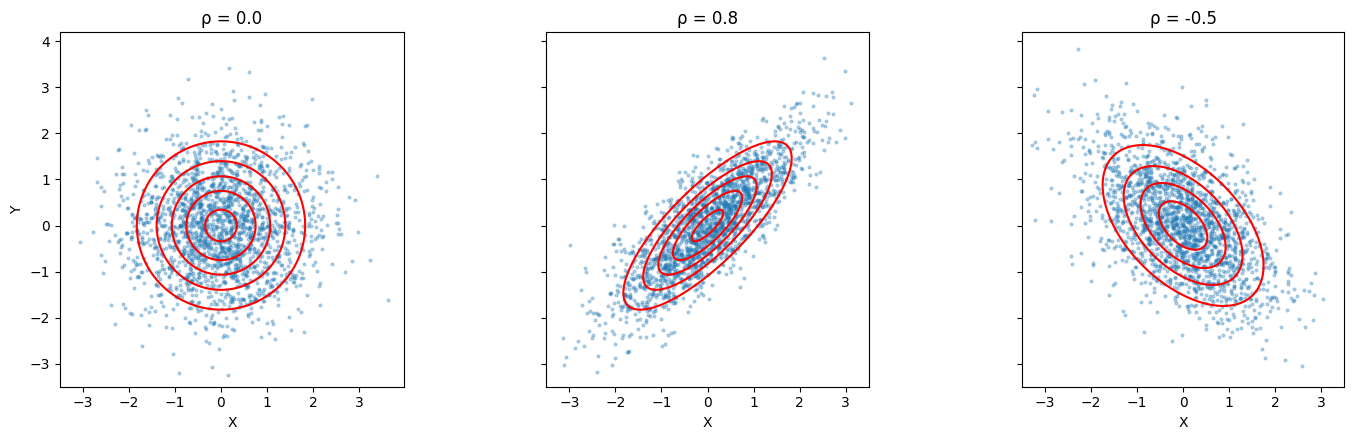

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, rho in zip(axes, [0.0, 0.8, -0.5]):
    cov = [[1, rho], [rho, 1]]          # variâncias 1, então a covariância é igual à correlação
    pontos = rng.multivariate_normal(mean=[0, 0], cov=cov, size=2_000)
    ax.scatter(pontos[:, 0], pontos[:, 1], s=4, alpha=0.3)   # [:, 0] = todas as linhas, coluna 0

    # Curvas de nível da densidade: avaliamos a PDF numa grade de pontos (np.meshgrid) e desenhamos com contour.
    gx, gy = np.meshgrid(np.linspace(-3.5, 3.5, 200), np.linspace(-3.5, 3.5, 200))
    densidade = stats.multivariate_normal([0, 0], cov).pdf(np.dstack([gx, gy]))   # dstack junta as grades em pares (x, y)
    ax.contour(gx, gy, densidade, levels=5, colors="red")
    ax.set_title(f"ρ = {rho}")
    ax.set_xlabel("X")
    ax.set_aspect("equal")   # mesma escala nos dois eixos, para não distorcer as elipses
axes[0].set_ylabel("Y")
plt.tight_layout()
plt.show()

In [7]:
# A média condicional é uma reta: com ρ = 0,8, E[Y | X = x] = 0,8·x.
pontos = rng.multivariate_normal([0, 0], [[1, 0.8], [0.8, 1]], size=200_000)
X, Y = pontos[:, 0], pontos[:, 1]
for x0 in [-2, -1, 0, 1, 2]:
    fatia = np.abs(X - x0) < 0.05             # os pontos com X muito perto de x0
    print(f"X ≈ {x0:+d}: E[Y | X] ≈ {Y[fatia].mean():+.3f}  (teoria: {0.8 * x0:+.1f})   desvio de Y na fatia: {Y[fatia].std():.3f}")
print(f"\nDesvio de Y sem condicionar: {Y.std():.3f}   teoria para a condicional: √(1 - ρ²) = {np.sqrt(1 - 0.8**2):.3f}")

X ≈ -2: E[Y | X] ≈ -1.604  (teoria: -1.6)   desvio de Y na fatia: 0.587
X ≈ -1: E[Y | X] ≈ -0.797  (teoria: -0.8)   desvio de Y na fatia: 0.597
X ≈ +0: E[Y | X] ≈ +0.000  (teoria: +0.0)   desvio de Y na fatia: 0.589
X ≈ +1: E[Y | X] ≈ +0.787  (teoria: +0.8)   desvio de Y na fatia: 0.600
X ≈ +2: E[Y | X] ≈ +1.579  (teoria: +1.6)   desvio de Y na fatia: 0.601

Desvio de Y sem condicionar: 0.998   teoria para a condicional: √(1 - ρ²) = 0.600


**Conclusão:** nos gráficos, com $\rho = 0$ as curvas de nível são **círculos**; com $\rho = 0{,}8$, elipses estreitas inclinadas para cima; com $\rho = -0{,}5$, elipses mais largas inclinadas para baixo. Quanto mais forte a correlação, mais "achatada" a elipse.

A simulação confirma que a média condicional é uma **reta**: para $X \approx 2$, a média de $Y$ é **1,579** (teoria: 1,6); para $X \approx -1$, **−0,797** (teoria: −0,8). E o desvio de $Y$ dentro de cada fatia é sempre perto de **0,60** = $\sqrt{1 - \rho^2}$, menor que o desvio de $Y$ sem condicionar (**0,998**). Saber $X$ **reduz a incerteza** sobre $Y$. Repare que $1 - \rho^2 = 0{,}36$: sobram 36% da variância, ou seja, $X$ explica $\rho^2 = 64\%$ dela, o $R^2$ do notebook 04.

## 2. Uma normal multivariada nos pinguins

Vamos ajustar uma normal multivariada ao comprimento e à profundidade do bico dos pinguins **Gentoo** (uma única espécie, para não cair no paradoxo de Simpson do notebook 04). Ajustar é simples: o vetor de médias é a média de cada coluna, e a matriz de covariância é a de covariância da amostra.

In [8]:
gentoo = pinguins[pinguins["species"] == "Gentoo"][["bill_length_mm", "bill_depth_mm"]]
media = gentoo.mean().to_numpy()
cov = gentoo.cov().to_numpy()
print("Vetor de médias:", media.round(2))
print("Matriz de covariância:\n", cov.round(3))
print(f"Correlação: {gentoo.corr().iloc[0, 1]:.3f}")   # .iloc acessa por posição (linha 0, coluna 1)

Vetor de médias: [47.57 15.  ]
Matriz de covariância:
 [[9.648 2.003]
 [2.003 0.972]]
Correlação: 0.654


## 🎓 Conceito: direções principais e distância de Mahalanobis

A matriz de covariância esconde duas informações geométricas muito úteis:

- **Direções principais:** os **autovetores** da matriz de covariância apontam para os eixos da elipse, e os **autovalores** dizem quanta variância existe em cada direção. A primeira direção principal é aquela em que os dados **mais variam**. É exatamente o que o **PCA** (análise de componentes principais) calcula.
- **Distância de Mahalanobis:** a distância "comum" (euclidiana) trata todas as direções igualmente. A de Mahalanobis mede a distância até o centro **em desvios padrão, levando em conta a correlação**: é o z-score em várias dimensões. Um ponto pode estar perto do centro em centímetros, mas "fora da elipse", contrariando a correlação dos dados, e por isso ser um outlier.

$$d_M(\mathbf{x}) = \sqrt{(\mathbf{x} - \boldsymbol{\mu})^T\, \Sigma^{-1}\, (\mathbf{x} - \boldsymbol{\mu})}$$

(Não se preocupe com a notação de matrizes: o numpy faz as contas.)

In [9]:
# Autovalores e autovetores da matriz de covariância (eigh é a versão para matrizes simétricas).
autovalores, autovetores = np.linalg.eigh(cov)
ordem = np.argsort(autovalores)[::-1]          # [::-1] inverte: do maior autovalor para o menor
autovalores, autovetores = autovalores[ordem], autovetores[:, ordem]
print("Variância em cada direção principal:", autovalores.round(3))
print(f"Fração da variância na 1ª direção: {autovalores[0] / autovalores.sum():.1%}")

# Conferindo com o PCA do scikit-learn.
pca = PCA().fit(gentoo)
print("PCA do scikit-learn (variância explicada):", pca.explained_variance_.round(3))
print("1ª direção (nossa):", autovetores[:, 0].round(3), "  (PCA):", pca.components_[0].round(3))

Variância em cada direção principal: [10.088  0.532]
Fração da variância na 1ª direção: 95.0%
PCA do scikit-learn (variância explicada): [10.088  0.532]
1ª direção (nossa): [-0.977 -0.215]   (PCA): [0.977 0.215]


Mais distantes pela distância euclidiana: [321, 253]
Mais distantes por Mahalanobis:           [253, 257]


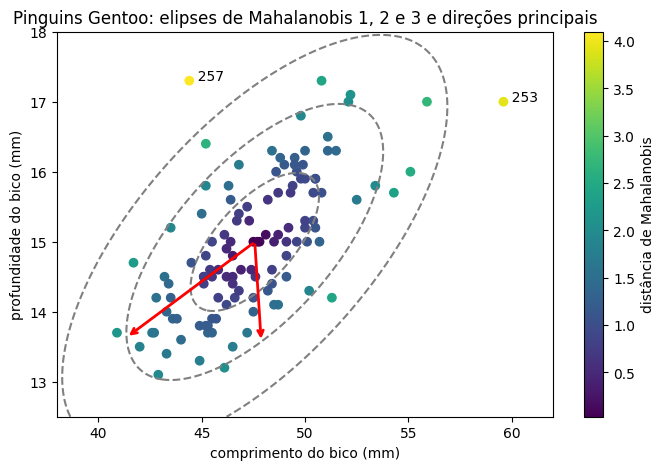

     bill_length_mm  bill_depth_mm  mahalanobis  euclidiana
321            55.9           17.0       2.7074      8.5694
253            59.6           17.0       3.9300     12.1976
257            44.4           17.3       4.0988      3.9169


In [10]:
# Distância de Mahalanobis de cada pinguim até o centro.
inversa = np.linalg.inv(cov)                  # a matriz inversa Σ⁻¹
desvios = gentoo.to_numpy() - media
# einsum calcula (x - μ)ᵀ Σ⁻¹ (x - μ) para cada linha de uma vez.
d_mahal = np.sqrt(np.einsum("ij,jk,ik->i", desvios, inversa, desvios))
d_euclid = np.sqrt(np.sum(desvios ** 2, axis=1))

# Os dois pinguins "mais estranhos" por cada critério.
print("Mais distantes pela distância euclidiana:", gentoo.index[np.argsort(d_euclid)[-2:]].tolist())
print("Mais distantes por Mahalanobis:          ", gentoo.index[np.argsort(d_mahal)[-2:]].tolist())

fig, ax = plt.subplots(figsize=(8, 5))
pontos_graf = ax.scatter(gentoo["bill_length_mm"], gentoo["bill_depth_mm"], c=d_mahal, cmap="viridis")
fig.colorbar(pontos_graf, label="distância de Mahalanobis")

# Elipses de 1, 2 e 3 "desvios padrão multivariados", e as direções principais saindo do centro.
gx, gy = np.meshgrid(np.linspace(38, 62, 300), np.linspace(12.5, 18, 300))
grade = np.dstack([gx - media[0], gy - media[1]])
d_grade = np.sqrt(np.einsum("...j,jk,...k->...", grade, inversa, grade))
ax.contour(gx, gy, d_grade, levels=[1, 2, 3], colors="gray", linestyles="--")
for valor, vetor in zip(autovalores, autovetores.T):
    ponta = media + 2 * np.sqrt(valor) * vetor
    ax.annotate("", xy=ponta, xytext=media, arrowprops={"arrowstyle": "->", "color": "red", "lw": 2})
for i in gentoo.index[np.argsort(d_mahal)[-2:]]:
    ax.annotate(f"  {i}", (gentoo.loc[i, "bill_length_mm"], gentoo.loc[i, "bill_depth_mm"]))
ax.set_xlabel("comprimento do bico (mm)")
ax.set_ylabel("profundidade do bico (mm)")
ax.set_title("Pinguins Gentoo: elipses de Mahalanobis 1, 2 e 3 e direções principais")
plt.show()

print(gentoo.assign(mahalanobis=d_mahal, euclidiana=d_euclid).sort_values("mahalanobis").tail(3))

**Conclusão:** nos Gentoo, a correlação entre comprimento e profundidade do bico é **0,654**. A primeira direção principal concentra **95,0%** da variância: os bicos variam sobretudo "ao longo da diagonal" (maiores em tudo ou menores em tudo). Os nossos autovalores (10,088 e 0,532) são **idênticos** aos do PCA do scikit-learn; a direção aparece com o sinal trocado, o que não muda nada (uma seta para trás aponta para a mesma reta). No gráfico, as setas não parecem perpendiculares porque os dois eixos têm escalas diferentes.

As duas distâncias discordam sobre quem é "estranho":
- Pela **euclidiana**, os mais distantes são os pinguins **321** e **253**, os dois de bico mais comprido (55,9 e 59,6 mm).
- Por **Mahalanobis**, o pinguim 321 tem distância **2,71**, dentro da elipse 3, porque bico comprido **com** bico profundo segue a correlação dos dados. Já o pinguim **257** está a só **3,92 mm** do centro, mas tem a maior distância de Mahalanobis (**4,10**): um bico **curto** (44,4 mm) e **profundo** (17,3 mm), uma combinação que contraria a correlação. O 253 continua estranho pelos dois critérios (3,93).

🔗 **Ponte para o ML:** é por isso que métodos baseados em distância (como o KNN do ML-02) dependem tanto da escala e da correlação dos atributos, e que a detecção de outliers em várias dimensões não pode olhar uma coluna de cada vez.

## 3. Resumo e próximos passos

**Conceitos que você aprendeu**
- Distribuições **conjunta**, **marginal** e **condicional**.
- **Esperança condicional** $E[Y \mid X]$, o alvo de toda regressão, e a lei da esperança total.
- $\text{Var}(X + Y) = \text{Var}(X) + \text{Var}(Y) + 2\,\text{Cov}(X, Y)$.
- **Correlação zero não implica independência.**
- **Normal multivariada**, **matriz de covariância** e a média condicional como uma **reta**.
- **Direções principais** (autovetores, a base do PCA) e a **distância de Mahalanobis**.

🔗 **Ponte para o ML:**
- A regressão linear do ML-01 estima $E[Y \mid X]$ supondo que ele seja uma reta (um plano, com vários atributos).
- O **PCA** encontra as direções principais da matriz de covariância para reduzir o número de colunas.
- Atributos com **covariância alta** entre si carregam informação repetida (a multicolinearidade do ML-01).

**Python novo:** `np.minimum`, `.str.replace`, `crosstab(normalize="all")`, `.div(axis=0)`, `.to_dict()`, `sns.stripplot`, `np.corrcoef`, `rng.multivariate_normal`, `np.meshgrid`, `np.dstack`, `ax.contour`, `set_aspect`, `.iloc`, `np.linalg.eigh` / `inv`, `np.argsort`, `[::-1]`, `np.einsum`, `.assign`.

**Próximo notebook:** com isso fechamos a Parte II (probabilidade). Na Parte III, vamos usar tudo o que vimos para responder à pergunta que ficou no ar desde o notebook 01: **quanto uma média calculada numa amostra pode errar?** O notebook 10 apresenta os dois teoremas mais importantes da estatística: a **Lei dos Grandes Números** e o **Teorema Central do Limite**.